# 4. Vetting a candidate

A peak from the period search is a candidate, not a planet. Four tools test it:
- `fold` shows the shape of the dip,
- `fit_transit` fits a physical model and reports the geometry,
- `odd_even` compares alternate transits, and
- `secondary_eclipse` looks for a second dip half an orbit later.

Each tool returns a verdict word with the numbers behind it. This notebook runs the
four on the strongest signal of the loaded episode.

The tools look for the usual impostors. The most common one is an eclipsing binary:
two stars that orbit each other and take turns to block each other's light. Its dips
can be as shallow as a planet's when the two stars are blended with a third, or when
one star only grazes the edge of the other. Each test below catches one way a binary
gives itself away.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("..").resolve()))
sys.path.insert(0, str(Path("../tests").resolve()))
plt.rcParams["figure.figsize"] = (11, 3.5)
plt.rcParams["figure.dpi"] = 110

EPISODES = Path("../data/episodes/s98_v2")


def load_episode(episode_id="ep_0001"):
    """Return (time, flux, truth) for one real episode, or a synthetic one if the set is absent."""
    if EPISODES.exists():
        from stargazer.episodes import EpisodeSet

        episode_set = EpisodeSet(EPISODES)
        time, flux, _ = episode_set.load(episode_id)
        return time, flux, episode_set.truth[episode_id]
    from conftest import synthetic_lc

    from stargazer.inject import inject, make_truth

    time, flux, _ = synthetic_lc(days=57.0)
    time = time - time.min()
    star = {"teff": 5500.0, "logg": 4.45, "radius_rsun": 0.95, "tmag": 10.0, "mass_msun": 0.95}
    truth = make_truth(period=0.7764, t0=0.1453, depth=0.0016, b=0.3, star=star)
    transit = {"period": truth.period, "t0": truth.t0, "duration": truth.duration, "depth": truth.depth}
    record = {"kind": "transit", "n_transits": 73, "snr": 60.0, "transit": transit}
    return time, inject(time, flux, truth), record


time, flux, truth = load_episode()
print(f"{len(time)} points over {time.max() - time.min():.1f} days; truth kind {truth['kind']}")

26521 points over 57.4 days; truth kind transit


In [2]:
from stargazer.tools import search_signals

candidate = search_signals(time, flux)["signals"][0]
print({key: candidate[key] for key in ("period", "t0", "duration", "depth_ppm", "sde")})

/home/siddharth899/personal_code/star_finder/.venv/lib/python3.13/site-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


{'period': 0.77639, 't0': 0.1453, 'duration': 0.051, 'depth_ppm': 1354.9, 'sde': 23.6}


## `fold`

The fold stacks every orbit on top of each other, as notebook 3 explains, and
returns the stacked curve in 40 bins. The output is short on purpose: the model
re-reads it on every later turn.

Each bin has:
- `phase`: the time from the transit centre, in days. Phase 0 is the centre of the dip.
- `flux_ppm`: the binned flux minus one, in parts per million. A flat star reads 0
  and a 1000 ppm transit reads about -1000 at phase 0.
- `depth_ppm`: the deepest bin.

The argument `phase_half_width` sets how much of the orbit to return, as a fraction
of the period. The two plots use the two useful settings:
- **0.5 shows the whole orbit**, from half a period before the dip to half a period
  after. Use it to look for a second dip. A second dip half way round means the
  candidate is a binary, or the true period is twice the trial one and the search
  folded two different eclipses onto each other.
- **0.05 zooms on the transit**, one twentieth of the orbit on each side. Use it to
  see the shape of the dip: flat bottom or V, and how wide it is.

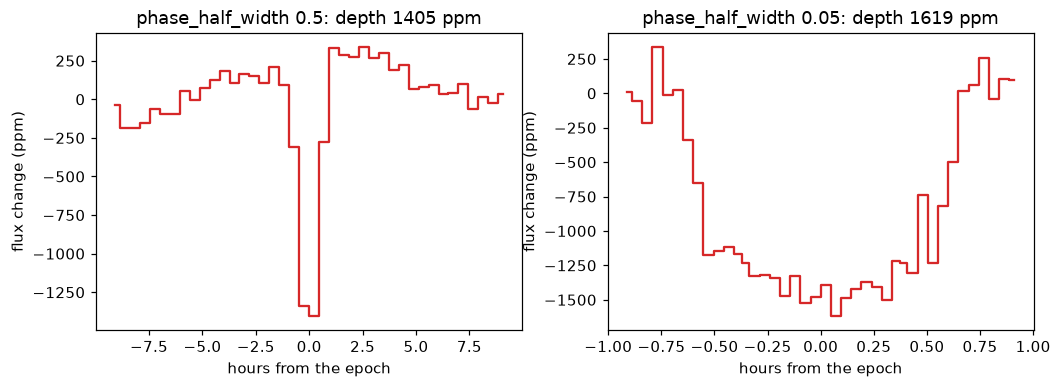

In [3]:
from stargazer.tools import fold

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for axis, width in zip(axes, (0.5, 0.05), strict=True):
    curve = fold(time, flux, period=candidate["period"], t0=candidate["t0"], phase_half_width=width)
    phases = np.array(curve["phase"], dtype=float)
    values = np.array([np.nan if value is None else value for value in curve["flux_ppm"]], dtype=float)
    axis.step(phases * 24, values, where="mid", color="tab:red")
    axis.set_xlabel("hours from the epoch")
    axis.set_ylabel("flux change (ppm)")
    axis.set_title(f"phase_half_width {width}: depth {curve['depth_ppm']:.0f} ppm")
plt.show()

## `fit_transit`

The box in notebook 3 was a crude shape. This tool fits a real transit curve, the
batman model, to the folded data. The curve has a round bottom from limb darkening,
the dimming of a star's disc towards its edge. Four numbers are free in the fit:
- the epoch offset, a small shift of the transit centre,
- `rp_rs`, the radius of the planet divided by the radius of the star,
- `a_rs`, the radius of the orbit divided by the radius of the star,
- `impact_parameter`, how far from the centre of the star the planet crosses. 0 is
  straight across the middle. 1 is along the edge.

The fit reports the depth as the square of `rp_rs`, the duration in hours and a
refined epoch. The two verdict words come from the geometry.

**The density verdict.** Kepler's third law links the period and the size of the
orbit to the mass of the star. With the orbit size in units of the star's radius, the
mass turns into a density:

$$\rho_\star = \frac{3 \pi}{G P^2} \left( \frac{a}{R_\star} \right)^3$$

So the fit says how dense the host star must be for a planet to make this dip at this
period. A normal star has a density between 0.1 and 20 grams per cubic centimetre,
and the verdict is `plausible` inside that range. A value outside it means the dip is
not a planet transit at this period. A blended binary or a wrong period both give an
impossible density.

**The shape verdict.** The sum of the impact parameter and the radius ratio says
whether the planet disc fits inside the star's disc at mid-transit. The shape is
`flat_bottom` when the sum is below 0.9: the whole planet is in front of the star for
a while, so the dip has a floor. The shape is `v_shaped` when the sum reaches 1: the
object only grazes the edge, so the dip is a V with no floor. Two grazing stars make a
V far more often than a planet does. The shape is `grazing_uncertain` between the two,
where the fit of a short transit cannot tell the two apart.

`significance_sigma` says how much better the transit curve fits than a flat line.
`n_bins` and `n_in_transit` are the number of bins the fit used and the number inside
the transit. The plot shows the binned fold with the fitted curve.

depth_ppm              1284.1
depth_err_ppm          2066.4
duration_hours         1.29
t0                     0.1455
rp_rs                  0.0358
a_rs                   4.04
impact_parameter       0.567
stellar_density_gcc    2.073
density_verdict        plausible
shape                  flat_bottom
significance_sigma     42.9
n_bins                 115
n_in_transit           15


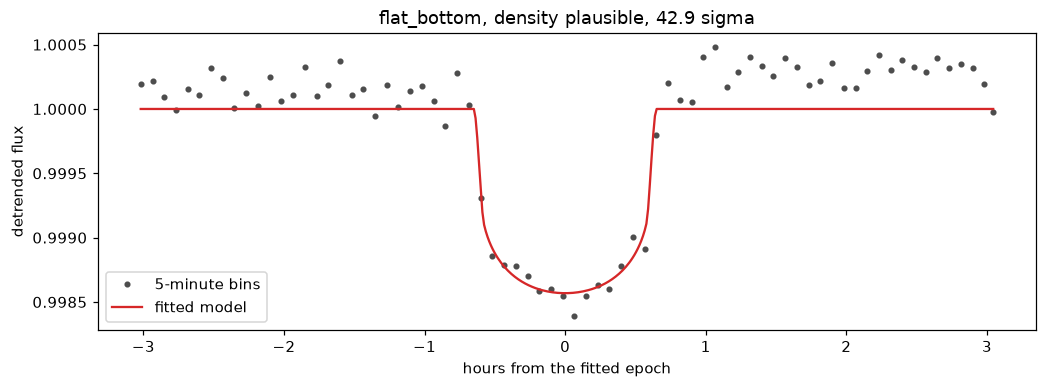

In [4]:
from stargazer.baseline import bin_lc, detrend
from stargazer.inject import TransitTruth, limb_darkening_for_teff, transit_model
from stargazer.tools import FIT_LIMB_DARKENING_TEFF, fit_transit

fit = fit_transit(time, flux, period=candidate["period"], t0=candidate["t0"], duration=candidate["duration"])
for key, value in fit.items():
    print(f"{key:22s} {value}")

flat_time, flat_flux = detrend(time, flux, 0.75)
period = candidate["period"]
phase = ((flat_time - fit["t0"] + 0.5 * period) % period) - 0.5 * period
window = np.abs(phase) < 2.5 * candidate["duration"]
bin_phase, bin_flux, _ = bin_lc(phase[window] + 2.5 * candidate["duration"], flat_flux[window], 5.0)
bin_phase = bin_phase - 2.5 * candidate["duration"]
u1, u2 = limb_darkening_for_teff(FIT_LIMB_DARKENING_TEFF)
inclination = float(np.degrees(np.arccos(min(fit["impact_parameter"], 0.999 * fit["a_rs"]) / fit["a_rs"])))
geometry = (fit["rp_rs"], fit["a_rs"], inclination, fit["impact_parameter"])
model = TransitTruth(period, 0.0, *geometry, u1, u2, 0.0, fit["rp_rs"] ** 2)
grid = np.linspace(bin_phase.min(), bin_phase.max(), 500)
fig, axis = plt.subplots()
axis.plot(bin_phase * 24, bin_flux, ".", color="0.3", label="5-minute bins")
axis.plot(grid * 24, transit_model(grid, model), color="tab:red", label="fitted model")
axis.set_xlabel("hours from the fitted epoch")
axis.set_ylabel("detrended flux")
axis.set_title(f"{fit['shape']}, density {fit['density_verdict']}, {fit['significance_sigma']} sigma")
axis.legend()
plt.show()

## `odd_even`

Two stars in a binary are not the same size and brightness, so the two eclipses in
one orbit have different depths. If the search lands on half the true period, it
folds the deep and the shallow eclipse onto each other and reports one dip. The
alternate transits then differ in depth: the first, third and fifth are the deep
eclipse and the second, fourth and sixth are the shallow one. A planet gives the
same dip every time.

The tool numbers the events in order and measures the depth of each. It averages the
odd-numbered and the even-numbered events, then compares the two averages:
- `odd_depth_ppm` and `even_depth_ppm`: the two average depths.
- `odd_events` and `even_events`: how many events went into each average.
- `difference_sigma`: the difference in the two depths, divided by its uncertainty.
  The uncertainty comes from how much the single events differ from each other, not
  from the point noise, so that leftover stellar variability counts.
- `verdict`: `consistent` below 3 sigma, `inconsistent` at or above it, and
  `insufficient_data` when either parity has fewer than two events.

In [5]:
from stargazer.tools import odd_even

parity = odd_even(time, flux, period=candidate["period"], t0=candidate["t0"], duration=candidate["duration"])
for key, value in parity.items():
    print(f"{key:18s} {value}")

odd_depth_ppm      1349.3
even_depth_ppm     1226.5
odd_events         24
even_events        24
difference_sigma   1.24
verdict            consistent


## `secondary_eclipse`

In a binary the smaller star shines too, so half an orbit after it passes in front
of the larger star it passes behind it. That makes a second, shallower dip at phase
0.5. A planet reflects too little light for its own secondary to show in one TESS
sector, so a second dip at phase 0.5 marks a binary.

The tool folds the detrended flux and measures the depth of a box, one transit
duration wide, at 200 phases around the orbit. The spread of those 200 depths is the
noise. Phases within three durations of the primary are left out of the noise and of
the search, because the detrending leaves a residual around a deep dip.
- `primary_depth_ppm`: the depth at phase 0, for comparison.
- `secondary_depth_ppm` and `secondary_sigma`: the depth at phase 0.5 and that depth
  divided by the noise.
- `strongest_other_phase`, `strongest_other_depth_ppm` and `strongest_other_sigma`:
  the deepest box at any phase away from the primary. A strong dip at a phase other
  than 0.5 means the period is wrong or a second signal is present.
- `noise_ppm`: the noise, from the spread of the trial depths.
- `verdict`: `secondary_at_half_phase` if the phase-0.5 depth reaches 3 sigma,
  `dip_at_other_phase` if the strongest other dip reaches 5 sigma, else
  `no_secondary`.

The plot shows the 200 trial depths across the orbit. The line at phase 0.5 marks
where a binary's second eclipse would be.

primary_depth_ppm          1287.5
secondary_depth_ppm        45.1
secondary_sigma            0.8
strongest_other_phase      0.57
strongest_other_depth_ppm  176.5
strongest_other_sigma      2.16
noise_ppm                  96.1
verdict                    no_secondary


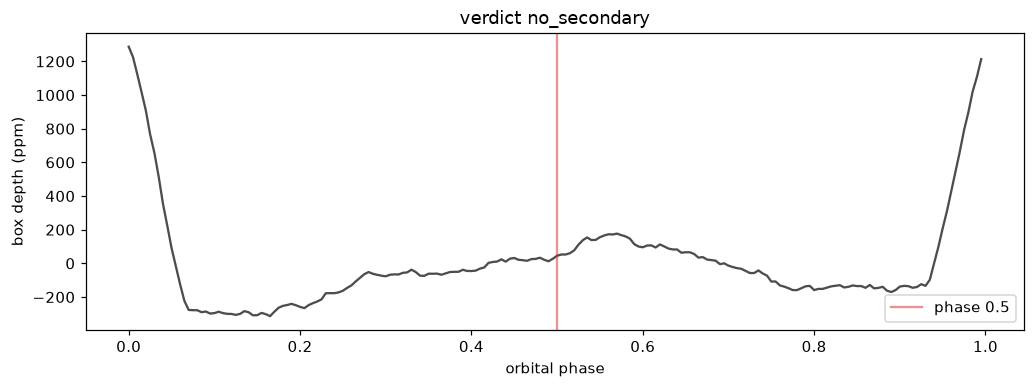

In [6]:
from stargazer.tools import secondary_eclipse

second = secondary_eclipse(
    time, flux, period=candidate["period"], t0=candidate["t0"], duration=candidate["duration"]
)
for key, value in second.items():
    print(f"{key:26s} {value}")

phase_orbit = ((flat_time - candidate["t0"]) / period) % 1.0
half_width = 0.5 * candidate["duration"] / period
trials = np.arange(200) / 200
depths = []
for trial in trials:
    offset = np.abs(((phase_orbit - trial + 0.5) % 1.0) - 0.5)
    points = flat_flux[offset < half_width]
    depths.append((1.0 - points.mean()) * 1e6 if len(points) >= 3 else np.nan)
fig, axis = plt.subplots()
axis.plot(trials, depths, color="0.3")
axis.axvline(0.5, color="tab:red", alpha=0.5, label="phase 0.5")
axis.set_xlabel("orbital phase")
axis.set_ylabel("box depth (ppm)")
axis.set_title(f"verdict {second['verdict']}")
axis.legend()
plt.show()